In [51]:
import pandas as pd
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

RAW = Path("..") / "data" / "raw"
PROC = Path("..") / "data" / "processed"

train = pd.read_csv(RAW / "Train.csv")
print("\nTraining data columns:",train.columns.tolist(),"\n")
print("Training data shape:",train.shape,"\n")
print(train.isna().sum())


Training data columns: ['ID', 'Longitude', 'Latitude', 'start_date', 'end_date', 'horizon_lower', 'horizon_upper', 'Depth_cm', 'Al', 'B', 'Ca', 'C_organic', 'C_total', 'Cu', 'electrical_conductivity', 'Fe', 'Mg', 'Mn', 'N', 'ph', 'P', 'K', 'Na', 'S', 'Zn'] 

Training data shape: (44298, 25) 

ID                             0
Longitude                      0
Latitude                       0
start_date                     0
end_date                       0
horizon_lower                  0
horizon_upper                  0
Depth_cm                       0
Al                             2
B                          42389
Ca                             0
C_organic                      0
C_total                     1950
Cu                            41
electrical_conductivity    42391
Fe                            41
Mg                             0
Mn                            43
N                             41
ph                             3
P                          42389
K           

In [52]:

# checking the structure of the data
print("Training data info:")
train.info()

Training data info:
<class 'pandas.DataFrame'>
RangeIndex: 44298 entries, 0 to 44297
Data columns (total 25 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   ID                       44298 non-null  str    
 1   Longitude                44298 non-null  float64
 2   Latitude                 44298 non-null  float64
 3   start_date               44298 non-null  str    
 4   end_date                 44298 non-null  str    
 5   horizon_lower            44298 non-null  int64  
 6   horizon_upper            44298 non-null  int64  
 7   Depth_cm                 44298 non-null  str    
 8   Al                       44296 non-null  float64
 9   B                        1909 non-null   float64
 10  Ca                       44298 non-null  float64
 11  C_organic                44298 non-null  float64
 12  C_total                  42348 non-null  float64
 13  Cu                       44257 non-null  float64
 14  electrical_co

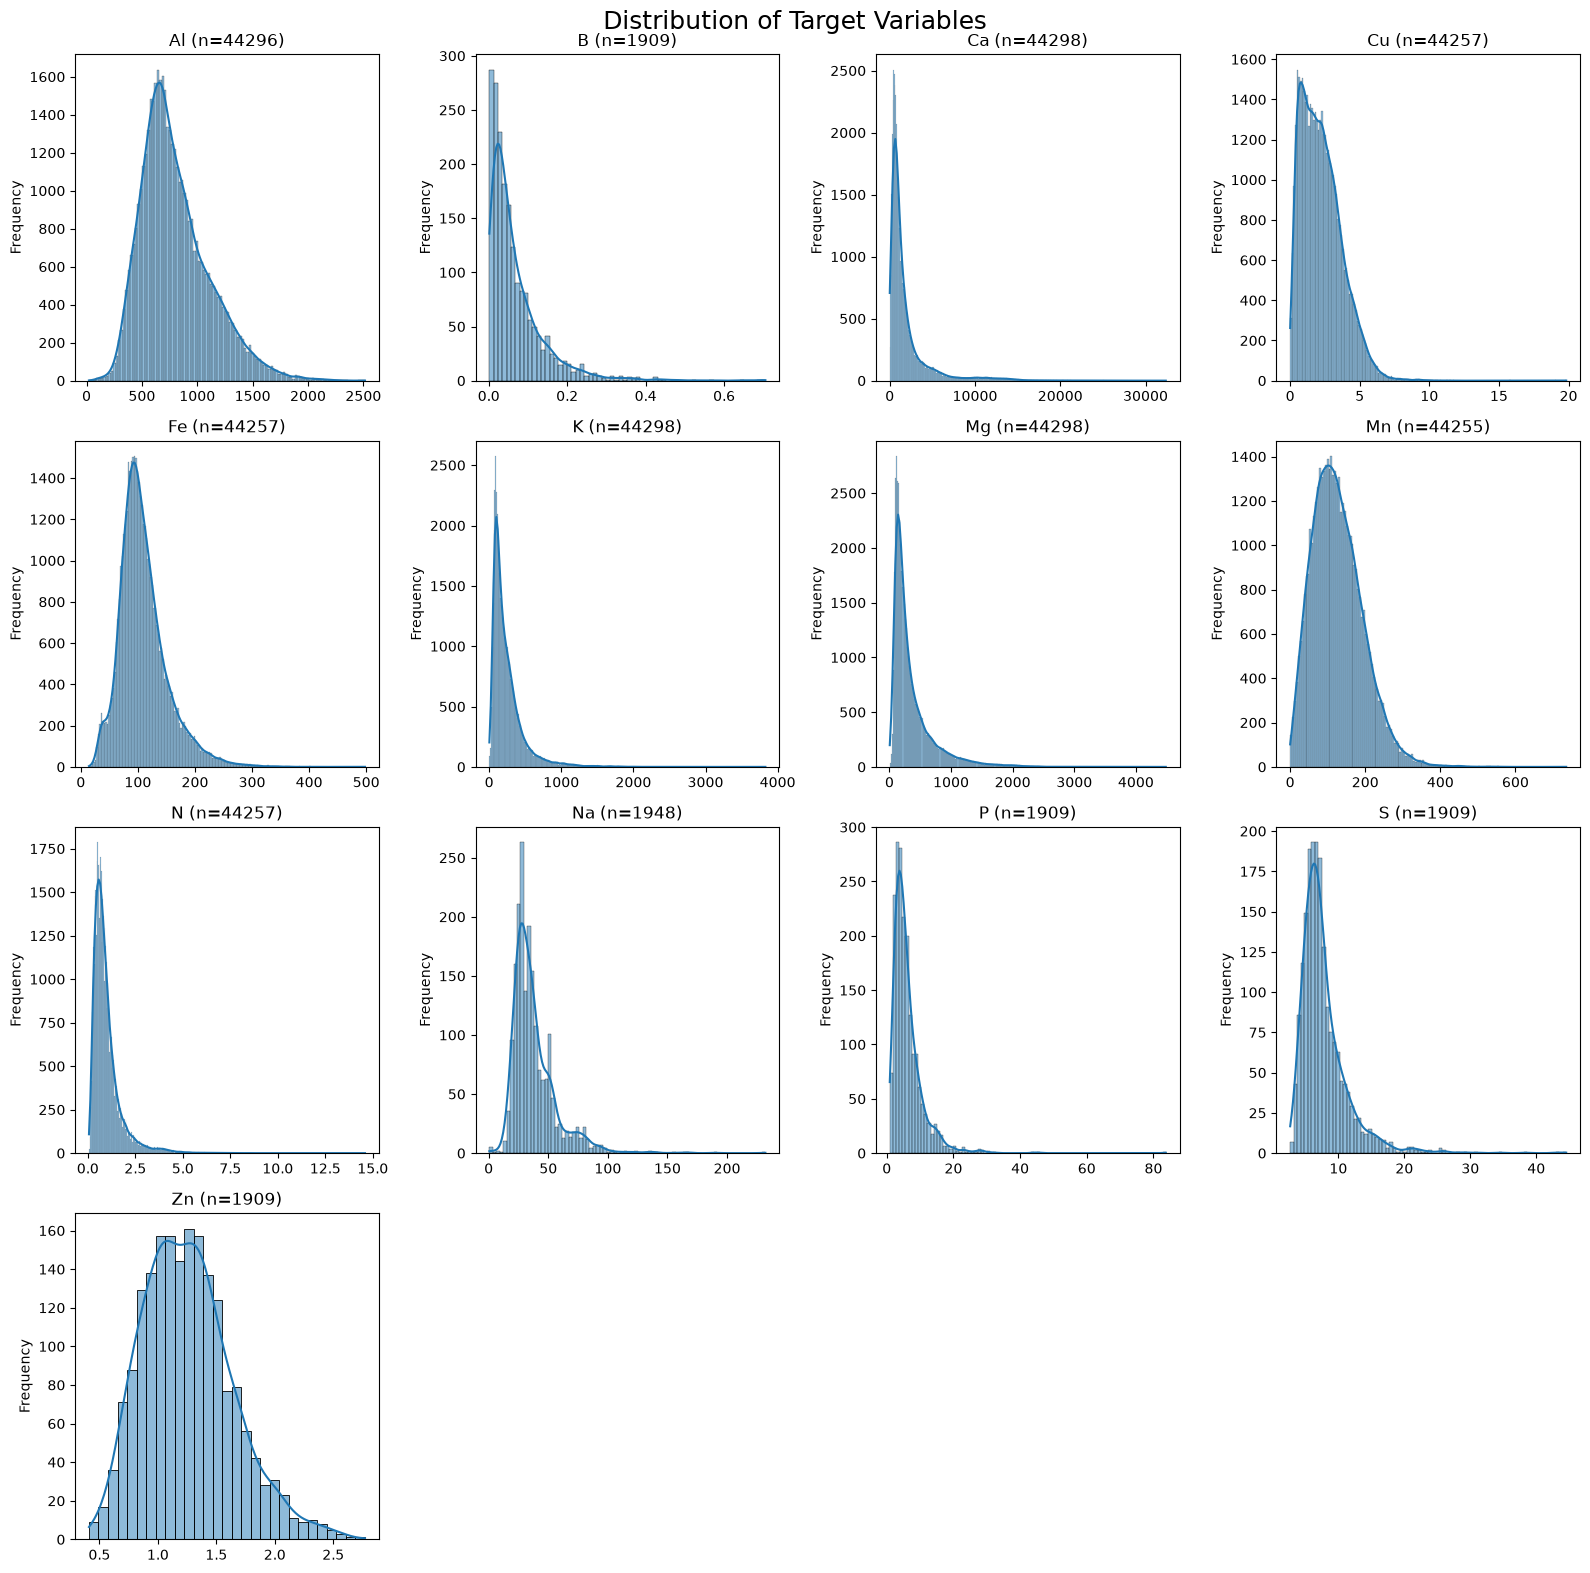

In [53]:
# checking the distribution of the target variables
targets = ["Al", "B", "Ca", "Cu", "Fe", "K", "Mg", "Mn", "N", "Na", "P", "S", "Zn"]

n_col = 4
n_row = -(-len(targets)//n_col)

# setting the figure layout
fig, axes = plt.subplots(n_row, n_col, figsize = (16, 4*n_row))
axes = axes.flatten()

for ax, target in zip(axes, targets):
    values = train[target].dropna()
    sns.histplot(values, kde=len(values)>1, ax=ax)
    ax.set_title(f"{target} (n={len(values)})")
    ax.set_xlabel("")
    ax.set_ylabel("Frequency")

for ax in axes[len(targets):]:
    ax.set_visible(False)


fig.suptitle("Distribution of Target Variables", fontsize = 18)
fig.tight_layout()
plt.show()

print()


In [45]:
skew = train[targets].skew().sort_values(ascending=False)
print(skew.round(2))

P     4.31
Ca    3.49
K     3.13
S     3.00
N     2.89
B     2.87
Na    2.60
Mg    2.56
Fe    1.27
Cu    0.95
Al    0.91
Mn    0.80
Zn    0.59
dtype: float64


In [59]:
feats_bio = pd.read_csv(PROC/"worldclim_train.csv")
feats_mon = pd.read_csv(PROC/"worldclim_monthly_train.csv")
# groups for cross_validatioin
groups = train.groupby(["Latitude", "Longitude"]).ngroup()
print(groups.nunique())

34823


In [61]:
import numpy as np
from sklearn.model_selection import GroupKFold
from lightgbm import LGBMRegressor

def cv_model_vs_mean(X, y, groups, seed=42):
    mask = y.notna()
    X, y, g = X[mask], y[mask], groups[mask]
    model_scores, mean_scores = [], []
    for tr, va in GroupKFold(n_splits=5).split(X, y, g):
        model = LGBMRegressor(n_estimators=500, learning_rate=0.05,
                              random_state=seed, verbose=-1)
        model.fit(X.iloc[tr], y.iloc[tr])
        actual = y.iloc[va].values
        pred = model.predict(X.iloc[va])
        mean_pred = np.full(len(va), y.iloc[tr].mean())
        model_scores.append(np.sqrt(np.mean((pred - actual) ** 2)))
        mean_scores.append(np.sqrt(np.mean((mean_pred - actual) ** 2)))
    return np.mean(model_scores), np.mean(mean_scores)

rows = []
for t in TARGETS:
    m_rmse, mean_rmse = cv_model_vs_mean(feats_bio, train[t], groups)
    rows.append({"target": t, "model_rmse": m_rmse, "mean_rmse": mean_rmse,
                 "improvement_pct": 100 * (mean_rmse - m_rmse) / mean_rmse})

baseline = pd.DataFrame(rows)
baseline.round(3)

,target,model_rmse,mean_rmse,improvement_pct
0,Al,169.806,309.630,45.158
1,B,0.069,0.073,5.369
2,Ca,1350.209,2595.362,47.976
3,Cu,0.963,1.449,33.532
4,Fe,31.459,42.323,25.669
5,K,135.014,228.600,40.939
6,Mg,202.281,351.152,42.395
7,Mn,48.151,67.223,28.372
8,N,0.500,0.763,34.429
9,Na,17.932,19.005,5.644


In [62]:
RESULTS = Path("..") / "results"
RESULTS.mkdir(exist_ok=True)
baseline.to_csv(RESULTS / "baseline_bio_raw.csv", index=False)

In [63]:
rows_mon = []
for t in TARGETS:
    m_rmse, mean_rmse = cv_model_vs_mean(feats_mon, train[t], groups)
    rows_mon.append({"target": t, "model_rmse": m_rmse, "mean_rmse": mean_rmse,
                 "improvement_pct": 100 * (mean_rmse - m_rmse) / mean_rmse})

baseline_mon = pd.DataFrame(rows_mon)
baseline_mon.round(3)

,target,model_rmse,mean_rmse,improvement_pct
0,Al,169.506,309.630,45.255
1,B,0.069,0.073,5.070
2,Ca,1346.779,2595.362,48.108
3,Cu,0.960,1.449,33.716
4,Fe,31.402,42.323,25.805
5,K,134.864,228.600,41.004
6,Mg,202.113,351.152,42.443
7,Mn,48.049,67.223,28.523
8,N,0.500,0.763,34.402
9,Na,17.904,19.005,5.792


In [64]:
baseline_mon.to_csv(RESULTS/"baseline_monthly_raw.csv", index=False)

In [67]:
compare_feats = baseline.merge(baseline_mon, on="target", suffixes=("_bio", "_mon"))
compare_feats[["target", "model_rmse_bio", "model_rmse_mon",
               "improvement_pct_bio", "improvement_pct_mon"]].round(3)

,target,model_rmse_bio,model_rmse_mon,improvement_pct_bio,improvement_pct_mon
0,Al,169.806,169.506,45.158,45.255
1,B,0.069,0.069,5.369,5.070
2,Ca,1350.209,1346.779,47.976,48.108
3,Cu,0.963,0.960,33.532,33.716
4,Fe,31.459,31.402,25.669,25.805
5,K,135.014,134.864,40.939,41.004
6,Mg,202.281,202.113,42.395,42.443
7,Mn,48.151,48.049,28.372,28.523
8,N,0.500,0.500,34.429,34.402
9,Na,17.932,17.904,5.644,5.792


In [68]:
def random_group_folds(groups, seed, n_splits=5):
    """Assign each location to a fold at random, keeping all its samples together."""
    rng = np.random.default_rng(seed)
    unique = groups.unique()
    fold_of = dict(zip(unique, rng.integers(0, n_splits, len(unique))))
    return groups.map(fold_of).values

def cv_seeded(X, y, groups, seed, n_splits=5):
    mask = y.notna()
    X, y, g = X[mask], y[mask], groups[mask]
    folds = random_group_folds(g, seed, n_splits)
    scores = []
    for k in range(n_splits):
        tr, va = folds != k, folds == k
        model = LGBMRegressor(n_estimators=500, learning_rate=0.05,
                              random_state=seed, verbose=-1)
        model.fit(X[tr], y[tr])
        pred = model.predict(X[va])
        scores.append(np.sqrt(np.mean((pred - y[va].values) ** 2)))
    return np.mean(scores)

SEEDS = [42, 7, 123]
seed_rows = []
for t in TARGETS:
    scores = [cv_seeded(feats_bio, train[t], groups, s) for s in SEEDS]
    seed_rows.append({"target": t,
                      **{f"rmse_seed{s}": sc for s, sc in zip(SEEDS, scores)},
                      "mean": np.mean(scores),
                      "std": np.std(scores, ddof=1),
                      "spread_pct": 100 * np.std(scores, ddof=1) / np.mean(scores)})

seed_check = pd.DataFrame(seed_rows)
seed_check.round(3)

,target,rmse_seed42,rmse_seed7,rmse_seed123,mean,std,spread_pct
0,Al,170.555,170.548,170.563,170.555,0.008,0.005
1,B,0.069,0.070,0.069,0.069,0.000,0.607
2,Ca,1358.320,1364.099,1361.358,1361.259,2.891,0.212
3,Cu,0.970,0.968,0.969,0.969,0.001,0.128
4,Fe,31.496,31.595,31.517,31.536,0.052,0.165
5,K,135.735,135.697,136.507,135.979,0.457,0.336
6,Mg,204.120,203.918,204.456,204.165,0.272,0.133
7,Mn,48.341,48.367,48.436,48.381,0.049,0.101
8,N,0.501,0.504,0.503,0.503,0.002,0.302
9,Na,17.966,17.641,17.953,17.854,0.184,1.029


In [69]:
seed_check.to_csv(RESULTS / "seed_check_bio.csv", index=False)